### NPD loc.parquet generation

In [1]:
import pandas as pd
import os
from pathlib import Path
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

from fastai.learner import *
from fastai.metrics import accuracy
from fastai.losses import CrossEntropyLossFlat, FocalLossFlat, LabelSmoothingCrossEntropyFlat
import time

from geoxts.benchmark_data import *
from tsai.all import TSDatasets, TSDataLoaders, TSStandardize, Categorize, combine_split_data
from tsai.all import FCN, LSTM, XCM, LSTM_FCN
from geoxts.benchmark_models import *

import torch
from torch.utils.data import Dataset, DataLoader

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

In [ ]:
# Set WARM = True if the kernel already has data in memory (ran full pipeline earlier)
# Set WARM = False for cold start: load pre-computed .npz + warm_state.pkl, skip data prep
#
# Cold start workflow: run Cell 1 (imports) → this cell (WARM=False) → skip to "Load datasets" cell
WARM = False

# ── Depth feature toggle ──────────────────────────────────────────────────────────────────────
USE_DEPTH = False           # Set True to include Depth as a model input feature
DEPTH_BOUNDS = [0, 18000]  # Min-max normalization bounds for Depth (feet)
_DEPTH_TAG = "_depth" if USE_DEPTH else ""

# ── Save directory: depth/ or no_depth/ ──────────────────────────────────────────────────────
# OLD: artifacts saved to project root with suffix only
# NEW: artifacts saved to a subdirectory (depth/ or no_depth/)
_SAVE_DIR = Path("depth") if USE_DEPTH else Path("no_depth")
_SAVE_DIR.mkdir(exist_ok=True)
print(f"USE_DEPTH={USE_DEPTH}, _DEPTH_TAG={_DEPTH_TAG!r}, _SAVE_DIR={_SAVE_DIR}")

In [3]:

# Paths
ROOT_PATH = Path().resolve() 
NPD_WELLLOGS_DIR = ROOT_PATH / "Data_NPD" / "npd_welllogs"
METADATA_PATH = ROOT_PATH / "Data_NPD" / "npd_metadata" / "tops_conditioned_corr.csv"
OUTPUT_PARQUET = ROOT_PATH / "Data_NPD" / "loc.parquet"
COMBINED_PARQUET = ROOT_PATH / "Data_NPD" / "npd_welllogs_combined.parquet"


In [4]:
print('Reading metadata...')
df_tops = pd.read_csv(METADATA_PATH, usecols=['wellbore_name', 'latitude', 'longitude'])

print('Path to well logs:', NPD_WELLLOGS_DIR)
print('Path to metadata:', METADATA_PATH)
print('Output path for Parquet file:', OUTPUT_PARQUET)

Reading metadata...
Path to well logs: C:\DSBA\DSBA_projects\CRP\geox\Data_NPD\npd_welllogs
Path to metadata: C:\DSBA\DSBA_projects\CRP\geox\Data_NPD\npd_metadata\tops_conditioned_corr.csv
Output path for Parquet file: C:\DSBA\DSBA_projects\CRP\geox\Data_NPD\loc.parquet


In [5]:
# Unique locations
df_locs = df_tops.drop_duplicates(subset=['wellbore_name']).set_index('wellbore_name')

# Rename columns/index to match schema
df_locs = df_locs.rename(columns={'latitude': 'Latitude', 'longitude': 'Longitude'})
df_locs.index.name = 'well_name'

# Wells available as parquet files
parquet_files = [
    f for f in os.listdir(NPD_WELLLOGS_DIR)
    if f.endswith('.parquet') and f != 'loc.parquet'
]
well_names = [Path(f).stem for f in parquet_files]

# Filter to wells with parquet logs
df_locs_filtered = df_locs.loc[df_locs.index.intersection(well_names)]

# Save
df_locs_filtered.to_parquet(OUTPUT_PARQUET)
print(f"Saved loc.parquet with {len(df_locs_filtered)} wells to {OUTPUT_PARQUET}")
display(df_locs_filtered.head())


Saved loc.parquet with 1377 wells to C:\DSBA\DSBA_projects\CRP\geox\Data_NPD\loc.parquet


,Latitude,Longitude
well_name,,
1_2_1,56.89,2.48
1_2_2,56.99,2.50
1_3_1,56.86,2.85
1_3_10,56.93,2.71
1_3_10_A,56.93,2.71


### NPD Tops.parquet generation

In [6]:
import pandas as pd
# Load NPD top train data
df_tops = pd.read_csv(METADATA_PATH)

# Pivot to create columns for each top containing their depths
pivoted_tops = df_tops.pivot_table(index='wellbore_name', columns='valid_marker_name', values='depth')

# Rename the index to match the structure of tops.parquet
pivoted_tops.index.name = 'well_name'

# Save the structured dataframe to npd_tops.parquet
pivoted_tops.to_parquet('npd_tops.parquet')
print('npd_tops.parquet successfully created with shape:', pivoted_tops.shape)


npd_tops.parquet successfully created with shape: (1709, 6)


In [7]:
well= pd.read_parquet('npd_tops.parquet', engine='fastparquet')
well.head()

valid_marker_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING
well_name,,,,,,
None,NaN,751.31236,1607.61160,1935.69560,7460.63016,NaN
None,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN
None,NaN,1479.65884,2139.10768,2562.33604,5049.21276,NaN
None,NaN,721.78480,1692.91344,2152.23104,NaN,NaN
None,NaN,1410.76120,3356.29932,3438.32032,NaN,NaN


In [8]:
well.shape

(1709, 6)

In [9]:
import pandas as pd
from pathlib import Path

# ---------------- Paths ----------------
OUT_LOC = ROOT_PATH / "Data_NPD" / "loc.parquet"
OUT_TOPS = ROOT_PATH / "Data_NPD" / "npd_tops.parquet"
OUT_MERGED = ROOT_PATH / "Data_NPD" / "npd_tops_with_loc.parquet"


In [10]:

# ---------------- Config ----------------
target_tops = ["HORDALAND", "ROGALAND", "SHETLAND", "VIKING", "VESTLAND", "DUNLIN"]

# ---------------- Load once ----------------
df_raw = pd.read_csv(METADATA_PATH)


In [11]:

# ---------------- Keep only wells that have a parquet welllog ----------------
parquet_wells = {f.stem for f in NPD_WELLLOGS_DIR.glob("*.parquet")} - {"loc"}
# If your parquet filenames match df_raw["wellbore_name"], this will work directly.
# If not, we can normalize names, but try this first.

# ---------------- Build loc table ----------------
df_loc = (
    df_raw.loc[:, ["wellbore_name", "latitude", "longitude"]]
      .drop_duplicates(subset=["wellbore_name"])
      .set_index("wellbore_name")
      .rename(columns={"latitude": "Latitude", "longitude": "Longitude"})
)
df_loc.index.name = "well_name"

# filter to wells we actually have logs for
df_loc = df_loc.loc[df_loc.index.intersection(parquet_wells)]

# ---------------- Filter tops then pivot ----------------
df_tops = df_raw[
    (df_raw["marker_name"].isin(target_tops)) &
    (df_raw["outlier"] != -1) &
    (df_raw["valid_presence"] == True)
].copy()

# If the correct column to pivot on is valid_marker_name, keep it.
# Otherwise, use marker_name. Pick ONE consistently.
pivot_col = "valid_marker_name" if "valid_marker_name" in df_tops.columns else "marker_name"

df_tops_pivot = (
    df_tops.pivot_table(
        index="wellbore_name",
        columns=pivot_col,
        values="depth",
        aggfunc="first"   # in case duplicates exist
    )
)
df_tops_pivot.index.name = "well_name"

# filter to wells we actually have logs for
df_tops_pivot = df_tops_pivot.loc[df_tops_pivot.index.intersection(parquet_wells)]

# ---------------- Save the two parquet files (optional) ----------------
df_loc.to_parquet(OUT_LOC)
df_tops_pivot.to_parquet(OUT_TOPS)

# ---------------- Merge them into one parquet ----------------
# Join on index (well_name). "left" keeps only wells that have tops.
df_merged = df_tops_pivot.join(df_loc, how="left")

# (optional) if you want to keep ALL wells that have logs, even if no tops:
# df_merged = df_loc.join(df_tops_pivot, how="left")

df_merged.to_parquet(OUT_MERGED)

print("loc:", df_loc.shape)
print("tops:", df_tops_pivot.shape)
print("merged:", df_merged.shape)
display(df_merged.head())


loc: (1377, 2)
tops: (1324, 6)
merged: (1324, 8)


,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,Latitude,Longitude
well_name,,,,,,,,
10_4_1,NaN,751.31236,1607.61160,1935.69560,7460.63016,NaN,57.68,5.16
10_5_1,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN,57.58,5.59
10_7_1,NaN,1479.65884,2139.10768,2562.33604,5049.21276,NaN,57.47,5.06
10_8_1,NaN,721.78480,1692.91344,NaN,NaN,NaN,57.42,5.57
11_10_1,NaN,1410.76120,3356.29932,3438.32032,NaN,NaN,57.01,6.17


In [12]:

# ---------------- Keep only wells that have a parquet welllog ----------------
parquet_wells = {f.stem for f in NPD_WELLLOGS_DIR.glob("*.parquet")} - {"loc"}
# If your parquet filenames match df_raw["wellbore_name"], this will work directly.
# If not, we can normalize names, but try this first.

# ---------------- Build loc table ----------------
df_loc = (
    df_raw.loc[:, ["wellbore_name", "latitude", "longitude"]]
      .drop_duplicates(subset=["wellbore_name"])
      .set_index("wellbore_name")
      .rename(columns={"latitude": "Latitude", "longitude": "Longitude"})
)
df_loc.index.name = "well_name"

# filter to wells we actually have logs for
df_loc = df_loc.loc[df_loc.index.intersection(parquet_wells)]

# ---------------- Filter tops then pivot ----------------
df_tops = df_raw[
    (df_raw["marker_name"].isin(target_tops)) &
    (df_raw["outlier"] != -1) &
    (df_raw["valid_presence"] == True)
].copy()

# If the correct column to pivot on is valid_marker_name, keep it.
# Otherwise, use marker_name. Pick ONE consistently.
pivot_col = "valid_marker_name" if "valid_marker_name" in df_tops.columns else "marker_name"

df_tops_pivot = (
    df_tops.pivot_table(
        index="wellbore_name",
        columns=pivot_col,
        values="depth",
        aggfunc="first"   # in case duplicates exist
    )
)
df_tops_pivot.index.name = "well_name"

# filter to wells we actually have logs for
df_tops_pivot = df_tops_pivot.loc[df_tops_pivot.index.intersection(parquet_wells)]

# ---------------- Save the two parquet files (optional) ----------------
df_loc.to_parquet(OUT_LOC)
df_tops_pivot.to_parquet(OUT_TOPS)

# ---------------- Merge them into one parquet ----------------
# Join on index (well_name). "left" keeps only wells that have tops.
df_merged = df_tops_pivot.join(df_loc, how="left")

# (optional) if you want to keep ALL wells that have logs, even if no tops:
# df_merged = df_loc.join(df_tops_pivot, how="left")

df_merged.to_parquet(OUT_MERGED)

print("loc:", df_loc.shape)
print("tops:", df_tops_pivot.shape)
print("merged:", df_merged.shape)
display(df_merged.head())


loc: (1377, 2)
tops: (1324, 6)
merged: (1324, 8)


,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,Latitude,Longitude
well_name,,,,,,,,
10_4_1,NaN,751.31236,1607.61160,1935.69560,7460.63016,NaN,57.68,5.16
10_5_1,NaN,623.35960,885.82680,1099.08140,4829.39648,NaN,57.58,5.59
10_7_1,NaN,1479.65884,2139.10768,2562.33604,5049.21276,NaN,57.47,5.06
10_8_1,NaN,721.78480,1692.91344,NaN,NaN,NaN,57.42,5.57
11_10_1,NaN,1410.76120,3356.29932,3438.32032,NaN,NaN,57.01,6.17


In [13]:
df_logs = pd.read_parquet(COMBINED_PARQUET)
df_logs.head()

,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name
0,97.027901,NaN,NaN,NaN,NaN,383.660099,30_10_3
1,96.591103,NaN,NaN,NaN,NaN,384.160099,30_10_3
2,96.081902,NaN,NaN,NaN,NaN,384.660099,30_10_3
3,94.928596,NaN,NaN,NaN,NaN,385.160099,30_10_3
4,93.775299,NaN,NaN,NaN,NaN,385.660099,30_10_3


In [14]:
#print first non nan in deepres_clean
first_non_nan_ln = df_logs['DEEPRES_CLEAN'].dropna().iloc[0]

In [15]:
#correct ln to through exponential log10 transformation on DEEPRES_CLEAN
if 'DEEPRES_CLEAN' in df_logs.columns:
    df_logs['DEEPRES_CLEAN'] = np.exp(df_logs['DEEPRES_CLEAN'])
    df_logs['DEEPRES_CLEAN'] = np.log10(df_logs['DEEPRES_CLEAN'])

In [16]:
first_non_nan_log = df_logs['DEEPRES_CLEAN'].dropna().iloc[0]
print("First non-NaN value in DEEPRES_CLEAN before vs after transformation:", first_non_nan_ln, first_non_nan_log)

First non-NaN value in DEEPRES_CLEAN before vs after transformation: -0.12261973198317062 -0.05325307297274669


In [17]:
# Min-max normalization applied column-wise using fixed physical bounds
# DEEPRES_log10 refers to DEEPRES_CLEAN after the log10 transformation above
min_max_dict = {
    "GR_CLEAN":       [0, 200],
    "RHOB_CLEAN":     [1.95, 2.95],
    "NEUT_CLEAN":     [-0.15, 0.7],
    "DTC_CLEAN":      [40, 240],
    "DEEPRES_log10":  [np.log10(0.1), np.log10(2000)],
}

col_rename = {"DEEPRES_log10": "DEEPRES_CLEAN"}  # maps dict key -> actual df column

for key, (lo, hi) in min_max_dict.items():
    col = col_rename.get(key, key)
    if col in df_logs.columns:
        df_logs[col] = ((df_logs[col] - lo) / (hi - lo)).clip(0, 1)     

print("Normalization applied. Sample statistics:")
display(df_logs[["GR_CLEAN", "RHOB_CLEAN", "NEUT_CLEAN", "DTC_CLEAN", "DEEPRES_CLEAN"]].describe())

Normalization applied. Sample statistics:


,GR_CLEAN,RHOB_CLEAN,NEUT_CLEAN,DTC_CLEAN,DEEPRES_CLEAN
count,2.884073e+07,1.486865e+07,1.204201e+07,1.505192e+07,2.718266e+07
mean,3.391687e-01,3.688038e-01,5.582074e-01,3.916890e-01,2.769589e-01
std,1.659729e-01,2.139188e-01,1.620238e-01,1.508154e-01,9.285517e-02
min,0.000000e+00,0.000000e+00,1.800000e-02,1.000000e-01,5.935149e-02
25%,2.237545e-01,1.850000e-01,4.474091e-01,2.630631e-01,2.182081e-01
50%,3.287855e-01,3.810001e-01,5.616471e-01,3.944521e-01,2.657829e-01
75%,4.361000e-01,5.481000e-01,6.707175e-01,5.193910e-01,3.163941e-01
max,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [18]:
# Ensure consistent naming
df_logs.rename(columns={"well_name": "well_name"}, inplace=True)
df_logs["well_name"] = df_logs["well_name"].astype(str)
df_merged.index = df_merged.index.astype(str)

# Merge (left join keeps all depth rows)
df_final = df_logs.merge(
    df_merged,
    on="well_name",
    how="left"
)

# Normalize Latitude and Longitude after merge
lat_lo, lat_hi = 56, 66
lon_lo, lon_hi = 1, 11
df_final["Latitude"]  = ((df_final["Latitude"]  - lat_lo) / (lat_hi - lat_lo)).clip(0, 1)
df_final["Longitude"] = ((df_final["Longitude"] - lon_lo) / (lon_hi - lon_lo)).clip(0, 1)

print("Final shape:", df_final.shape)
display(df_final.head())

Final shape: (31236076, 15)


,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,Latitude,Longitude
0,0.485140,NaN,NaN,NaN,NaN,383.660099,30_10_3,NaN,NaN,7099.73776,NaN,NaN,NaN,0.405,0.117
1,0.482956,NaN,NaN,NaN,NaN,384.160099,30_10_3,NaN,NaN,7099.73776,NaN,NaN,NaN,0.405,0.117
2,0.480410,NaN,NaN,NaN,NaN,384.660099,30_10_3,NaN,NaN,7099.73776,NaN,NaN,NaN,0.405,0.117
3,0.474643,NaN,NaN,NaN,NaN,385.160099,30_10_3,NaN,NaN,7099.73776,NaN,NaN,NaN,0.405,0.117
4,0.468876,NaN,NaN,NaN,NaN,385.660099,30_10_3,NaN,NaN,7099.73776,NaN,NaN,NaN,0.405,0.117


In [19]:
# Log data interpolation: bfill/ffill per well only.
# Rows still NaN after that (wells missing an entire log curve) are dropped
# rather than filled with a synthetic value (e.g. global median).
LOG_FEATURES = ['GR_CLEAN', 'RHOB_CLEAN', 'DTC_CLEAN', 'DEEPRES_CLEAN', 'NEUT_CLEAN']

df_final[LOG_FEATURES] = df_final.groupby('well_name')[LOG_FEATURES].transform(
    lambda s: s.bfill().ffill()
)

# Diagnostics: what's still NaN after bfill/ffill?
nan_per_col = df_final[LOG_FEATURES].isna().sum()
print("NaN remaining per column after bfill/ffill:")
print(nan_per_col)

wells_with_nan = df_final[df_final[LOG_FEATURES].isna().any(axis=1)]['well_name'].nunique()
print(f"\nWells with remaining NaN rows (entire curve missing): {wells_with_nan}")

# Drop rows where any log curve is still NaN (wells missing entire curves)
nan_before = len(df_final)
df_final = df_final.dropna(subset=LOG_FEATURES)
print(f"Dropped {nan_before - len(df_final)} rows ({(nan_before - len(df_final))/nan_before*100:.2f}%) with remaining NaN")

NaN remaining per column after bfill/ffill:
GR_CLEAN         1163391
RHOB_CLEAN       2357276
DTC_CLEAN        8364203
DEEPRES_CLEAN    1293837
NEUT_CLEAN       2822732
dtype: int64

Wells with remaining NaN rows (entire curve missing): 461
Dropped 9677112 rows (30.98%) with remaining NaN


In [20]:
WELL_COL = "well_name"
DEPTH_COL = "DS_INDEX"   # your depth axis
MARKERS = ["HORDALAND", "ROGALAND", "SHETLAND", "VIKING", "VESTLAND", "DUNLIN"]

# (a) per-well top depths (since repeated)
tops_wide = df_final[[WELL_COL] + MARKERS].groupby(WELL_COL).first().reset_index()


In [21]:
tops_wide.head(20)

,well_name,HORDALAND,ROGALAND,SHETLAND,VIKING,VESTLAND,DUNLIN
0,10_4_1,751.31236,1607.61160,1935.69560,NaN,7460.63016,NaN
1,10_5_1,623.35960,885.82680,1099.08140,NaN,4829.39648,NaN
2,10_7_1,1479.65884,2139.10768,2562.33604,NaN,5049.21276,NaN
3,15_12_1,4189.63268,7857.61180,8671.26012,9862.20504,10246.06332,NaN
4,15_12_10_S,4619.42272,8366.14200,9074.80344,10698.81924,11220.47280,NaN
5,15_12_11_S,4340.55132,8300.52520,9317.58560,10633.20244,11138.45180,NaN
6,15_12_12,4084.64580,7342.51992,8021.65380,9163.38612,NaN,NaN
7,15_12_13_B,4068.24160,7470.47268,8267.71680,9438.97668,9721.12892,NaN
8,15_12_14,4347.11300,7844.48844,8435.03964,9816.27328,10679.13420,NaN
9,15_12_15,4271.65368,8031.49632,8710.63020,NaN,10757.87436,NaN


In [22]:
# (b) long format: one row = one (well, marker, top_depth)
tops = (tops_wide
        .melt(id_vars=WELL_COL, value_vars=MARKERS,
              var_name="marker_name", value_name="top_depth")
        .dropna(subset=["top_depth"])
        .sort_values([WELL_COL, "top_depth"])
        .reset_index(drop=True))

In [23]:
tops.head(20)

,well_name,marker_name,top_depth
0,10_4_1,HORDALAND,751.31236
1,10_4_1,ROGALAND,1607.61160
2,10_4_1,SHETLAND,1935.69560
3,10_4_1,VESTLAND,7460.63016
4,10_5_1,HORDALAND,623.35960
5,10_5_1,ROGALAND,885.82680
6,10_5_1,SHETLAND,1099.08140
7,10_5_1,VESTLAND,4829.39648
8,10_7_1,HORDALAND,1479.65884
9,10_7_1,ROGALAND,2139.10768


In [24]:
#%pip install iterative-stratification


In [25]:
# Build train/val/test splits based on wells, stratified by marker presence (multi-label)
# build multi-hot label matrix per well
well_marker = (tops.assign(v=1)
               .pivot_table(index=WELL_COL, columns="marker_name", values="v",
                            fill_value=0, aggfunc="max")
               .astype(int))

# Prepare data for stratified split
wells = well_marker.index.to_numpy()
Y = well_marker.to_numpy()

# Stratified split parameters
test_size = 0.2
random_state = 42
n_splits = 1
test_size = 0.20
val_size  = 0.10 

# Stratified split
msss1 = MultilabelStratifiedShuffleSplit(test_size=test_size, random_state=random_state, n_splits=n_splits)
trainval_idx, test_idx = next(msss1.split(wells, Y))

wells_trainval = wells[trainval_idx]
Y_trainval = Y[trainval_idx]

wells_test = wells[test_idx]

val_size_within_trainval = val_size / (1.0 - test_size)

msss2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=val_size_within_trainval, random_state=random_state)
train_idx2, val_idx = next(msss2.split(wells_trainval, Y_trainval))

train_wells = set(wells_trainval[train_idx2])
val_wells   = set(wells_trainval[val_idx])
test_wells  = set(wells_test)

In [26]:
import numpy as np
import pandas as pd

def marker_freq(well_set, well_marker):
    """
    Compute marker counts and ratios for a given set of wells.

    Parameters:
    - well_set: set of well names to compute frequencies for
    - well_marker: DataFrame (index=well_name, columns=marker_name) multi-hot matrix

    Returns:
    - DataFrame with marker counts and ratios for the specified wells
    """
    well_sum = well_marker.loc[list(well_set)].sum()
    total = well_sum.sum()
    well_ratio = well_sum / total if total > 0 else well_sum * np.nan
    return pd.concat([well_sum, well_ratio], axis=1, keys=["count", "ratio"])


def check_splits(train_wells, val_wells, test_wells, well_marker, rtol=0.1):
    # ---- tables ----
    train_tab = marker_freq(train_wells, well_marker)
    val_tab   = marker_freq(val_wells, well_marker)
    test_tab  = marker_freq(test_wells, well_marker)

    # ---- overlap checks ----
    ov_tv = train_wells & val_wells
    ov_tt = train_wells & test_wells
    ov_vt = val_wells & test_wells

    if len(ov_tv) == 0 and len(ov_tt) == 0 and len(ov_vt) == 0:
        print("\nNo overlap between train/val/test wells")
    else:
        print("\nAttention overlap, fix split!")
        if ov_tv: print("train ∩ val:", sorted(list(ov_tv))[:20], "..." if len(ov_tv) > 20 else "")
        if ov_tt: print("train ∩ test:", sorted(list(ov_tt))[:20], "..." if len(ov_tt) > 20 else "")
        if ov_vt: print("val ∩ test:", sorted(list(ov_vt))[:20], "..." if len(ov_vt) > 20 else "")

    # ---- ratio closeness checks ----
    # compare ratios pairwise (train vs val, train vs test, val vs test)
    close_tv = np.isclose(train_tab["ratio"], val_tab["ratio"], equal_nan=True, rtol=rtol).all()
    close_tt = np.isclose(train_tab["ratio"], test_tab["ratio"], equal_nan=True, rtol=rtol).all()
    close_vt = np.isclose(val_tab["ratio"], test_tab["ratio"], equal_nan=True, rtol=rtol).all()

    print(f"\nRatios close (rtol={rtol}):")
    print("  train vs val :", close_tv)
    print("  train vs test:", close_tt)
    print("  val vs test  :", close_vt)

    # ---- counts ----
    print("\nSplit sizes (#wells):", len(train_wells), len(val_wells), len(test_wells))

    # ---- print tables ----
    print("\nTrain marker split:\n", train_tab)
    print("\nVal marker split:\n", val_tab)
    print("\nTest marker split:\n", test_tab)

    return train_tab, val_tab, test_tab

In [27]:
train_tab, val_tab, test_tab = check_splits(train_wells, val_wells, test_wells, well_marker, rtol=0.1)


No overlap between train/val/test wells

Ratios close (rtol=0.1):
  train vs val : True
  train vs test: True
  val vs test  : True

Split sizes (#wells): 679 96 197

Train marker split:
              count     ratio
marker_name                 
DUNLIN         174  0.073760
HORDALAND      585  0.247986
ROGALAND       573  0.242900
SHETLAND       552  0.233997
VESTLAND       124  0.052565
VIKING         351  0.148792

Val marker split:
              count     ratio
marker_name                 
DUNLIN          25  0.073964
HORDALAND       84  0.248521
ROGALAND        82  0.242604
SHETLAND        79  0.233728
VESTLAND        18  0.053254
VIKING          50  0.147929

Test marker split:
              count     ratio
marker_name                 
DUNLIN          50  0.073421
HORDALAND      171  0.251101
ROGALAND       165  0.242291
SHETLAND       158  0.232012
VESTLAND        36  0.052863
VIKING         101  0.148311


In [28]:
print("Train wells (top 5, sorted):", sorted(train_wells)[:5])
print("Val wells (top 5, sorted):", sorted(val_wells)[:5])
print("Test wells (top 5, sorted):", sorted(test_wells)[:5])

Train wells (top 5, sorted): ['10_4_1', '10_7_1', '15_12_1', '15_12_11_S', '15_12_13_B']
Val wells (top 5, sorted): ['15_12_12', '15_12_7_S', '15_3_3', '15_8_2', '15_9_14']
Test wells (top 5, sorted): ['10_5_1', '15_12_10_S', '15_12_14', '15_12_18_A', '15_12_18_S']


In [29]:
# Create train/test df
df_train = df_final[df_final[WELL_COL].isin(train_wells)].reset_index(drop=True)
df_val   = df_final[df_final[WELL_COL].isin(val_wells)].reset_index(drop=True)
df_test  = df_final[df_final[WELL_COL].isin(test_wells)].reset_index(drop=True)

In [30]:
# Well retention: keep all wells with at least one valid marker
# (do NOT drop wells with partial markers — classification models process
# one class at a time, so partial-marker wells still contribute training samples)
tops_train_diag = df_train[[WELL_COL] + MARKERS].groupby(WELL_COL).first()
tops_val_diag   = df_val[[WELL_COL] + MARKERS].groupby(WELL_COL).first()
tops_test_diag  = df_test[[WELL_COL] + MARKERS].groupby(WELL_COL).first()

print("Train wells:", len(tops_train_diag))
print("Val wells:  ", len(tops_val_diag))
print("Test wells: ", len(tops_test_diag))

print("\nNaN counts per marker (train):")
print(tops_train_diag[MARKERS].isna().sum())
print("\nNaN counts per marker (val):")
print(tops_val_diag[MARKERS].isna().sum())
print("\nNaN counts per marker (test):")
print(tops_test_diag[MARKERS].isna().sum())

Train wells: 679
Val wells:   96
Test wells:  197

NaN counts per marker (train):
HORDALAND     94
ROGALAND     106
SHETLAND     127
VIKING       328
VESTLAND     555
DUNLIN       505
dtype: int64

NaN counts per marker (val):
HORDALAND    12
ROGALAND     14
SHETLAND     17
VIKING       46
VESTLAND     78
DUNLIN       71
dtype: int64

NaN counts per marker (test):
HORDALAND     26
ROGALAND      32
SHETLAND      39
VIKING        96
VESTLAND     161
DUNLIN       147
dtype: int64


In [31]:
df_train.head()

,GR_CLEAN,RHOB_CLEAN,DTC_CLEAN,DEEPRES_CLEAN,NEUT_CLEAN,DS_INDEX,well_name,DUNLIN,HORDALAND,ROGALAND,SHETLAND,VESTLAND,VIKING,Latitude,Longitude
0,0.078633,0.616,0.554741,0.275034,0.741765,322.160095,7_11_9,NaN,NaN,9730.97144,10374.01608,13677.82196,NaN,0.12,0.141
1,0.058619,0.616,0.554741,0.275034,0.741765,322.660095,7_11_9,NaN,NaN,9730.97144,10374.01608,13677.82196,NaN,0.12,0.141
2,0.077941,0.616,0.554741,0.275034,0.741765,323.160095,7_11_9,NaN,NaN,9730.97144,10374.01608,13677.82196,NaN,0.12,0.141
3,0.091831,0.616,0.554741,0.275034,0.741765,323.660095,7_11_9,NaN,NaN,9730.97144,10374.01608,13677.82196,NaN,0.12,0.141
4,0.100071,0.616,0.554741,0.275034,0.741765,324.160095,7_11_9,NaN,NaN,9730.97144,10374.01608,13677.82196,NaN,0.12,0.141


In [32]:
d = df_train.sort_values(["well_name","DS_INDEX"]).groupby("well_name")["DS_INDEX"].diff()
print("Median step:", float(d.median()))

Median step: 0.5


In [33]:
# Redefine features list
FEATURES = ['GR_CLEAN', 'RHOB_CLEAN', 'DTC_CLEAN', 'DEEPRES_CLEAN', 'NEUT_CLEAN', 'Latitude', 'Longitude']

# Compatible with original features list from geox:
FEATURES_GEOX = ['GR', 'RHOB', 'DTC', 'DEEPRES', 'NEUT', 'Latitude', 'Longitude']

if USE_DEPTH:
    FEATURES_GEOX.append('Depth')

    # update Well_grlog_cleaning to normalize Depth consistently
    # in both extract_dataset_Xy (training) and get_markers (prediction)
    _original_wgc = Well_grlog_cleaning

    def _wgc_with_depth_norm(well_name, df_log, input_variable):
        df_wgr = _original_wgc(well_name, df_log, input_variable)
        if 'Depth' in df_wgr.columns:
            lo, hi = DEPTH_BOUNDS
            df_wgr['Depth'] = ((df_wgr['Depth'] - lo) / (hi - lo)).clip(0, 1)
        return df_wgr

    _wgc_with_depth_norm._depth_patched = True
    import geoxts.benchmark_data as _bd
    _bd.Well_grlog_cleaning = _wgc_with_depth_norm
    Well_grlog_cleaning = _wgc_with_depth_norm
    print(f"Depth feature enabled: bounds={DEPTH_BOUNDS}, features={FEATURES_GEOX}")

Depth feature enabled: bounds=[0, 18000], features=['GR', 'RHOB', 'DTC', 'DEEPRES', 'NEUT', 'Latitude', 'Longitude', 'Depth']


In [34]:
# -------------------------
# Stable well mapping (from original names)
# -------------------------
all_wells = np.array(sorted({str(w) for w in list(train_wells) + list(val_wells) + list(test_wells)}), dtype=object)
well_cat = pd.CategoricalDtype(categories=all_wells, ordered=True)

# -------------------------
# Convert logs to geoxts expected schema (wellName, DEPTH, features) with numeric types only.
# -------------------------
def to_geoxts_logs(df: pd.DataFrame) -> pd.DataFrame:
    # Select only needed cols up front (include Latitude and Longitude)
    cols = [WELL_COL, DEPTH_COL, "GR_CLEAN", "RHOB_CLEAN", "DTC_CLEAN", "DEEPRES_CLEAN", "NEUT_CLEAN", "Latitude", "Longitude"]
    out = df.loc[:, cols].rename(columns={
        WELL_COL: "wellName",
        DEPTH_COL: "DEPTH",
        "GR_CLEAN": "GR",
        "RHOB_CLEAN": "RHOB",
        "DTC_CLEAN": "DTC",
        "DEEPRES_CLEAN": "DEEPRES",
        "NEUT_CLEAN": "NEUT",
    })

    # Map wellName to numeric codes based on stable category (missing wells get -1 -> -1.0)
    out["wellName"] = out["wellName"].astype("string").astype(well_cat).cat.codes.astype("float64")

    # Numeric conversion in one shot + downcast to float32 to reduce memory bandwidth
    num_cols = ["DEPTH", "GR", "RHOB", "DTC", "DEEPRES", "NEUT", "Latitude", "Longitude"]
    out[num_cols] = out[num_cols].apply(pd.to_numeric, errors="coerce").astype("float32")

    # Drop missing wellName/depth (cat.codes gives -1 for unknown -> becomes -1.0)
    out = out[(out["wellName"] >= 0) & out["DEPTH"].notna()]
    out = out.reset_index(drop=True)

    return out

# -------------------------
# Convert tops to wide format indexed by numeric well ids, columns 0..K-1 (marker order),
# and make it NaN-safe (fill missing tops with 0.0) so geoxts' max(wtop[0]) never returns NaN.
# -------------------------
def to_geoxts_tops(tops_df: pd.DataFrame) -> pd.DataFrame:
    t = tops_df.rename(columns={WELL_COL: "wellName"}).copy()
    t["wellName"] = t["wellName"].astype(str).map(well2id)
    t["top_depth"] = pd.to_numeric(t["top_depth"], errors="coerce")

    wide = (
        t.pivot_table(
            index="wellName",
            columns="marker_name",
            values="top_depth",
            aggfunc="first",
        )
        .reindex(columns=MARKERS)
    )

    # rename columns to integer labels so tops.loc[well][i] works as label lookup
    wide.columns = list(range(len(MARKERS)))

    # *** critical: make max(wtop[0]) finite inside geoxts ***
    wide = wide.apply(pd.to_numeric, errors="coerce").fillna(0.0)

    return wide

In [35]:
# -------------------------
# Re-run with all logs together to ensure consistent wellName mapping across splits, then split by well.
# (This is because some wells may have been dropped in one split due to missing data, which would cause inconsistent category codes if we convert separately.)
# -------------------------
df_all_g = to_geoxts_logs(df_final)

# Split by well using the stable category mapping to numeric codes 
train_ids = pd.Index(pd.Series(list(train_wells), dtype="string").astype(well_cat).cat.codes).astype("float64")
val_ids   = pd.Index(pd.Series(list(val_wells),   dtype="string").astype(well_cat).cat.codes).astype("float64")
test_ids  = pd.Index(pd.Series(list(test_wells),  dtype="string").astype(well_cat).cat.codes).astype("float64")

df_train_g = df_all_g[df_all_g["wellName"].isin(train_ids)]
df_val_g   = df_all_g[df_all_g["wellName"].isin(val_ids)]
df_test_g  = df_all_g[df_all_g["wellName"].isin(test_ids)]

well2id = dict(zip(pd.Series(well_cat.categories, dtype="string").astype(well_cat).cat.codes, well_cat.categories))
well2id = {v: k for k, v in well2id.items()}

tops_g = to_geoxts_tops(tops)

# -------------------------
# Build marker-specific well lists (top_list_bool=1 expects well_list[i][0] to be a list)
# Keep only wells that exist in tops and have that marker (depth > 0)
# -------------------------
train_wells_g = sorted([well2id[str(w)] for w in train_wells if str(w) in well2id])
val_wells_g   = sorted([well2id[str(w)] for w in val_wells   if str(w) in well2id])
test_wells_g  = sorted([well2id[str(w)] for w in test_wells  if str(w) in well2id])

def wells_with_marker(tops_wide: pd.DataFrame, wells: list, marker_idx: int) -> list:
    wells = [w for w in wells if w in tops_wide.index]
    wells = [w for w in wells if tops_wide.loc[w, marker_idx] > 0]
    return sorted(wells)

well_list_train = [[wells_with_marker(tops_g, train_wells_g, i)] for i in range(len(MARKERS))]
well_list_val   = [[wells_with_marker(tops_g, val_wells_g,   i)] for i in range(len(MARKERS))]
well_list_test  = [[wells_with_marker(tops_g, test_wells_g,  i)] for i in range(len(MARKERS))]

# -------------------------
# Extract datasets
# -------------------------
X_train, y_train = extract_dataset_Xy(df_train_g, tops_g, well_list_train, FEATURES_GEOX, wsize=201, top_list_bool=1)
X_val,   y_val   = extract_dataset_Xy(df_val_g,   tops_g, well_list_val,   FEATURES_GEOX, wsize=201, top_list_bool=1)
X_test,  y_test  = extract_dataset_Xy(df_test_g,  tops_g, well_list_test,  FEATURES_GEOX, wsize=201, top_list_bool=1)

In [36]:
# Convert labels to int64 for classification task
y_train = y_train.astype(np.int64)
y_val   = y_val.astype(np.int64)
y_test  = y_test.astype(np.int64)

In [37]:
print("Train shapes:", X_train.shape, y_train.shape)
print("Val shapes:",   X_val.shape,   y_val.shape)
print("Test shapes:",  X_test.shape,  y_test.shape)

Train shapes: (22586, 8, 201) (22586,)
Val shapes: (3216, 8, 201) (3216,)
Test shapes: (6568, 8, 201) (6568,)


In [38]:
# Save datasets as numpy files
# OLD: np.savez_compressed(f"train{_DEPTH_TAG}.npz", X=X_train, y=y_train)
# NEW: save to _SAVE_DIR subdirectory
np.savez_compressed(_SAVE_DIR / f"train{_DEPTH_TAG}.npz", X=X_train, y=y_train)
np.savez_compressed(_SAVE_DIR / f"val{_DEPTH_TAG}.npz",   X=X_val,   y=y_val)
np.savez_compressed(_SAVE_DIR / f"test{_DEPTH_TAG}.npz",   X=X_test,  y=y_test)
print(f"Saved to {_SAVE_DIR}/: train{_DEPTH_TAG}.npz, val{_DEPTH_TAG}.npz, test{_DEPTH_TAG}.npz")

Saved train_depth.npz, val_depth.npz, test_depth.npz


In [39]:
import json as _json

# Save evaluation state for cold start (parquet + JSON — no pickle, avoids pandas version issues)
# OLD: saved to project root
# NEW: saved to _SAVE_DIR subdirectory
df_test_g.to_parquet(_SAVE_DIR / f"warm_df_test_g{_DEPTH_TAG}.parquet", index=False)
tops.to_parquet(_SAVE_DIR / f"warm_tops{_DEPTH_TAG}.parquet", index=False)
with open(_SAVE_DIR / f"warm_state{_DEPTH_TAG}.json", "w") as f:
    _json.dump({
        "test_wells": sorted(test_wells),
        "well2id": {str(k): v for k, v in well2id.items()},
        "MARKERS": MARKERS,
        "FEATURES_GEOX": FEATURES_GEOX,
        "WELL_COL": WELL_COL,
        "USE_DEPTH": USE_DEPTH,
        "DEPTH_BOUNDS": DEPTH_BOUNDS if USE_DEPTH else None,
    }, f)
print(f"Saved to {_SAVE_DIR}/: warm_df_test_g{_DEPTH_TAG}.parquet + warm_tops{_DEPTH_TAG}.parquet + warm_state{_DEPTH_TAG}.json")

Saved warm_df_test_g_depth.parquet + warm_tops_depth.parquet + warm_state_depth.json


In [40]:
'X_train' in locals()

True

In [41]:
import json as _json

if not WARM:
    # --- Cold start: load .npz arrays + evaluation state from _SAVE_DIR ---
    train_data = np.load(_SAVE_DIR / f"train{_DEPTH_TAG}.npz")
    X_train, y_train = train_data['X'], train_data['y']
    val_data = np.load(_SAVE_DIR / f"val{_DEPTH_TAG}.npz")
    X_val, y_val = val_data['X'], val_data['y']
    test_data = np.load(_SAVE_DIR / f"test{_DEPTH_TAG}.npz")
    X_test, y_test = test_data['X'], test_data['y']

    df_test_g = pd.read_parquet(_SAVE_DIR / f"warm_df_test_g{_DEPTH_TAG}.parquet")
    tops      = pd.read_parquet(_SAVE_DIR / f"warm_tops{_DEPTH_TAG}.parquet")
    with open(_SAVE_DIR / f"warm_state{_DEPTH_TAG}.json") as f:
        _ws = _json.load(f)
    test_wells    = set(_ws["test_wells"])
    well2id       = {str(k): v for k, v in _ws["well2id"].items()}
    MARKERS       = _ws["MARKERS"]
    FEATURES_GEOX = _ws["FEATURES_GEOX"]
    WELL_COL      = _ws["WELL_COL"]

    # Re-apply depth normalization monkey-patch for prediction
    # (Cell 34 is skipped during cold start, so the patch is not yet active)
    if _ws.get("USE_DEPTH") and 'Depth' in FEATURES_GEOX \
       and not getattr(Well_grlog_cleaning, '_depth_patched', False):
        DEPTH_BOUNDS = _ws["DEPTH_BOUNDS"]
        _original_wgc = Well_grlog_cleaning

        def _wgc_with_depth_norm(well_name, df_log, input_variable):
            df_wgr = _original_wgc(well_name, df_log, input_variable)
            if 'Depth' in df_wgr.columns:
                lo, hi = DEPTH_BOUNDS
                df_wgr['Depth'] = ((df_wgr['Depth'] - lo) / (hi - lo)).clip(0, 1)
            return df_wgr

        _wgc_with_depth_norm._depth_patched = True
        import geoxts.benchmark_data as _bd
        _bd.Well_grlog_cleaning = _wgc_with_depth_norm
        Well_grlog_cleaning = _wgc_with_depth_norm
        print(f"  Depth normalization re-applied: bounds={DEPTH_BOUNDS}")

    del _ws
    print(f"Cold start: loaded from {_SAVE_DIR}/ (USE_DEPTH={USE_DEPTH})")
else:
    print("Warm path: using in-memory data")

Cold start: loaded .npz + parquet + JSON state (USE_DEPTH=True)


In [42]:
# Combine train + val with split indices for tsai's TSDatasets
X, y, splits = combine_split_data([X_train, X_val], [y_train, y_val])
tfms  = [None, [Categorize()]]
dsets = TSDatasets(X, y, tfms=tfms, splits=splits, inplace=True)

# Create tensor dataloader
dls = TSDataLoaders.from_dsets(dsets.train, dsets.valid, bs=25, batch_tfms=[], num_workers=0) 
#dls = TSDataLoaders.from_dsets(dsets.train, dsets.valid, bs=25, num_workers=0) 

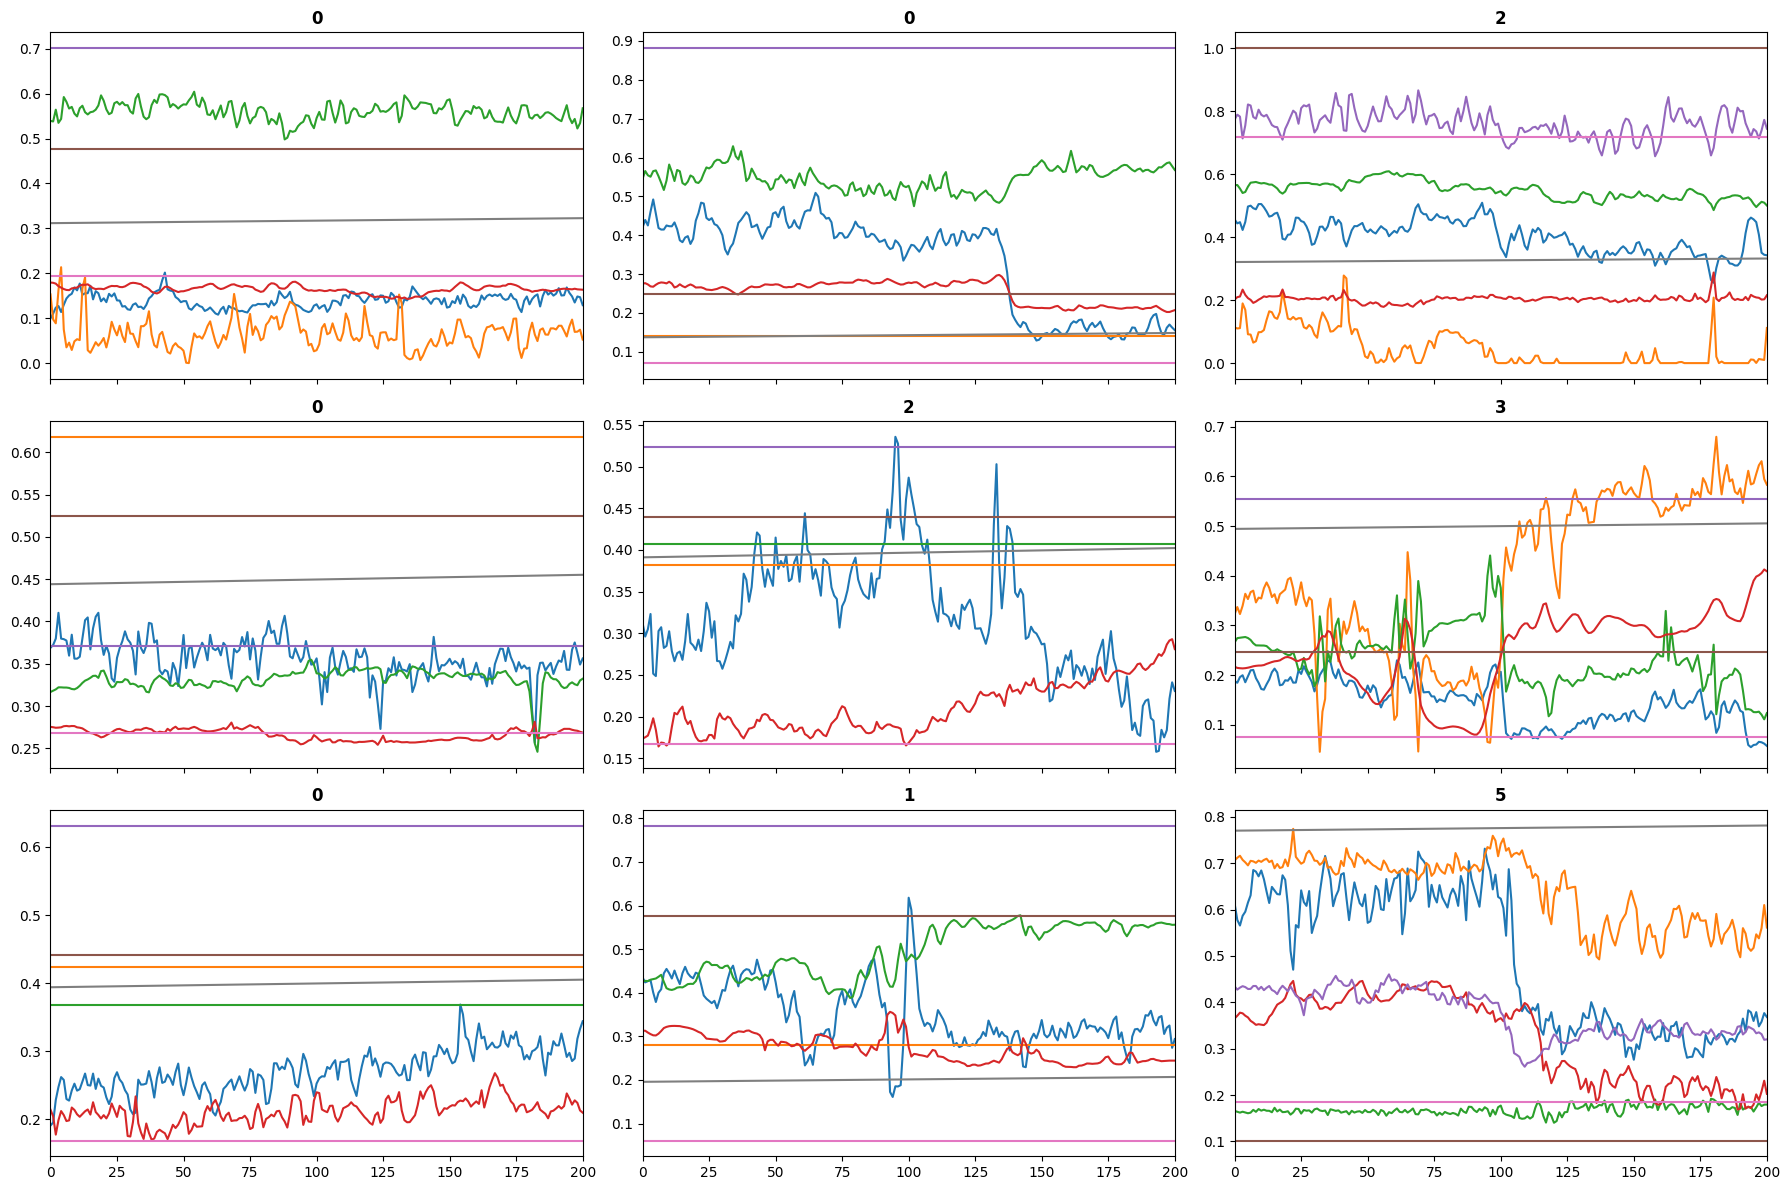

In [43]:
valid_dl = dls.valid
dls.show_batch()

In [44]:
xb, yb = dls.one_batch()
yb

TensorCategory([2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 3, 0, 0, 2, 3, 6, 1, 3, 0, 0, 0,
                4, 0, 0, 0])

In [45]:
# Fix random seed AND enforce fully deterministic CUDA for reproducible training.
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'   # required by torch deterministic mode

random_seed(0, use_cuda=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# OLD: warn_only=True — warns but does NOT enforce, results still vary between runs.
# torch.use_deterministic_algorithms(True, warn_only=True)

# NEW: warn_only=False — raises RuntimeError on any non-deterministic op.
# If this crashes, the error message names the exact op to investigate.
torch.use_deterministic_algorithms(True)
print("Fully deterministic mode enabled")

In [ ]:
#archs = [(LSTM_2dCNN, {}), (LSTM_XCM, {}), (LSTM_FCN, {})]
archs = [(LSTM_FCN, {})]

In [47]:
from IPython.display import clear_output, display
from fastai.callback.tracker import EarlyStoppingCallback, SaveModelCallback

# --- Use numeric-coded test data (df_test_g already has numeric wellName) ---
_test_log = df_test_g

# Test tops: wide format indexed by numeric well codes, columns = MARKERS (keep NaN for recall_tops)
_test_tops = (
    tops[tops[WELL_COL].isin(test_wells)]
    .assign(wellName=lambda d: d[WELL_COL].map(well2id))
    .pivot_table(index="wellName", columns="marker_name", values="top_depth", aggfunc="first")
    .reindex(columns=MARKERS)
)
_test_tops.index.name = "wellName"

pred_column = ['None'] + MARKERS
input_variable = FEATURES_GEOX
wsize = 201


In [ ]:
# --- Adapted Predicted_well_depth for N markers (original hardcodes 3) ---
import gc as _gc
import sys as _sys

def Predicted_well_depth_npd(df_test_log, df_test_tops, dls, learn, pred_column, wsize, valid_dl, input_variable):
    well_list = list(df_test_tops.index)
    col = df_test_tops.reset_index().columns.tolist()

    # OLD: passed full df_test_log (4M rows, 161 MB) to get_markers for every well,
    # which scans and copies the full frame each time — major memory pressure on VMs.
    # NEW: pre-group by well so each get_markers call receives only its own subset.
    _well_groups = dict(list(df_test_log.groupby('wellName')))

    # OLD: df_tops_pred = pd.DataFrame(columns=col) then pd.concat per well (slow, memory-heavy)
    # NEW: collect rows as dicts, build DataFrame once at the end
    rows = []
    skipped = []

    for wi, well in enumerate(well_list):
        try:
            well_tops = df_test_tops.loc[well]
            existing_markers = well_tops.dropna().index.tolist()
            # OLD: get_markers(df_test_log, ...)  — full 4M-row frame
            # NEW: get_markers(_well_groups.get(well, df_test_log.iloc[:0]), ...) — only this well's rows
            well_log = _well_groups.get(well, df_test_log.iloc[:0])
            pred_m, df_wm = get_markers(well_log, learn, dls, well, pred_column, wsize, valid_dl, input_variable, existing_markers)
            row = {col[0]: well}
            for j, depth in enumerate(pred_m):
                row[col[j + 1]] = depth
            rows.append(row)
            del df_wm, pred_m
        except Exception as e:
            skipped.append(well)
            continue

        # Progress + memory monitoring every 25 wells
        if (wi + 1) % 25 == 0 or (wi + 1) == len(well_list):
            gpu_mem = ""
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
                a = torch.cuda.memory_allocated() / 1e9
                r = torch.cuda.memory_reserved() / 1e9
                gpu_mem = f" | GPU: {a:.2f}GB alloc, {r:.2f}GB reserved"
            try:
                import resource
                rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
                cpu_mem = f" | RSS: {rss:.1f}GB"
            except Exception:
                cpu_mem = ""
            msg = "  Predicting: " + str(wi+1) + "/" + str(len(well_list)) + " wells" + gpu_mem + cpu_mem
            print(chr(13) + msg, end="")
            _sys.stdout.flush()
            _gc.collect()

    print()  # newline after progress
    del _well_groups
    _gc.collect()

    if skipped:
        print(f"  Skipped {len(skipped)}/{len(well_list)} wells (insufficient non-NaN log coverage for wsize={wsize})")

    df_tops_pred = pd.DataFrame(rows, columns=col).set_index(col[0])
    return df_tops_pred

: 

In [ ]:
# --- Training & evaluation loop ---
results = pd.DataFrame(columns=['arch', 'hyperparams', 'total params', 'train loss', 'valid loss', 'accuracy', 'time'])
result_recall = pd.DataFrame(columns=['arch', 'hyperparams', 'mae', 'recall', 'max_error', 'Run time'])

RECALL_TOLERANCE = 50
USE_CONFUSION_MATRIX = False  # Set True to display confusion matrix for each model

# ── Loss function selector ────────────────────────────────────────────────────
# OLD: USE_CLASS_WEIGHTED_LOSS = True/False toggle with inverse-frequency weights.
# NEW: LOSS_TYPE string selector — one place to pick from multiple options.
#
# Options:
#   "ce"           — vanilla CrossEntropyLoss (baseline)
#   "cwl"          — inverse-frequency class-weighted CE
#   "cwl_sqrt"     — sqrt-dampened class weights (gentler than cwl)
#   "ens"          — Effective Number of Samples weighting (Cui et al., 2019, beta=0.99)
#   "focal"        — Focal Loss (gamma=2), downweights easy examples
#   "focal_cwl"    — Focal Loss + inverse-frequency class weights
#   "focal_ens"    — Focal Loss + ENS class weights
#   "label_smooth" — Label Smoothing CE (eps=0.1)
LOSS_TYPE = "ce"

# ── Compute all weight variants ───────────────────────────────────────────────
_classes, _counts = np.unique(y_train, return_counts=True)

# Inverse-frequency: total / (n_classes * count_i)
_cw_full = len(y_train) / (len(_classes) * _counts)

# Sqrt-dampened: sqrt(inverse-freq), rescaled so min = 1
_cw_sqrt = np.sqrt(_cw_full); _cw_sqrt /= _cw_sqrt.min()

# Effective Number of Samples (Cui et al. 2019): w_i = (1 - beta) / (1 - beta^n_i)
ENS_BETA = 0.999
_ens = (1 - ENS_BETA) / (1 - ENS_BETA ** _counts)
_cw_ens = _ens / _ens.min()  # normalize so smallest weight = 1

def _to_weight_tensor(weights):
    w = np.zeros(int(_classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(_classes, weights):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)

_cw_full_t = _to_weight_tensor(_cw_full)
_cw_sqrt_t = _to_weight_tensor(_cw_sqrt)
_cw_ens_t  = _to_weight_tensor(_cw_ens)

def _build_loss(loss_type, device):
    """Return (loss_func, description_string) for the given loss_type."""
    if loss_type == "ce":
        return CrossEntropyLossFlat(), "CrossEntropy (vanilla)"
    elif loss_type == "cwl":
        return CrossEntropyLossFlat(weight=_cw_full_t.to(device)), \
               f"CE + inv-freq weights {dict(zip(_classes.astype(int), _cw_full.round(3)))}"
    elif loss_type == "cwl_sqrt":
        return CrossEntropyLossFlat(weight=_cw_sqrt_t.to(device)), \
               f"CE + sqrt weights {dict(zip(_classes.astype(int), _cw_sqrt.round(3)))}"
    elif loss_type == "ens":
        return CrossEntropyLossFlat(weight=_cw_ens_t.to(device)), \
               f"CE + ENS weights (beta={ENS_BETA}) {dict(zip(_classes.astype(int), _cw_ens.round(3)))}"
    elif loss_type == "focal":
        return FocalLossFlat(gamma=2.0), "FocalLoss (gamma=2)"
    elif loss_type == "focal_cwl":
        return FocalLossFlat(gamma=2.0, weight=_cw_full_t.to(device)), \
               f"FocalLoss (gamma=2) + inv-freq weights"
    elif loss_type == "focal_ens":
        return FocalLossFlat(gamma=2.0, weight=_cw_ens_t.to(device)), \
               f"FocalLoss (gamma=2) + ENS weights (beta={ENS_BETA})"
    elif loss_type == "label_smooth":
        return LabelSmoothingCrossEntropyFlat(eps=0.1), "LabelSmoothing (eps=0.1)"
    else:
        raise ValueError(f"Unknown LOSS_TYPE: {loss_type!r}")

print(f"LOSS_TYPE = {LOSS_TYPE!r}")
print(f"ENS weights (beta={ENS_BETA}): {dict(zip(_classes.astype(int), _cw_ens.round(3)))}")

# Class labels for confusion matrix display
pred_labels = pred_column  # ['None', 'HORDALAND', 'ROGALAND', ...]

for i, (arch, k) in enumerate(archs):
    model = build_model(arch, dls=dls, **k)
    print(model.__class__.__name__)

    device = next(model.parameters()).device
    loss_func, loss_desc = _build_loss(LOSS_TYPE, device)
    learn = Learner(dls, model, loss_func=loss_func, metrics=accuracy)
    if i == 0:
        print(f"  Loss: {loss_desc}")

    start = time.time()
    learn.fit_one_cycle(20, 1e-3, cbs=[
        EarlyStoppingCallback(monitor='valid_loss', patience=6),
        SaveModelCallback(monitor='valid_loss')
    ])
    elapsed = time.time() - start
    vals = learn.recorder.values[-1]

    # -- Confusion matrix on validation set --
    val_preds, val_targs = learn.get_preds(dl=valid_dl)
    val_pred_classes = val_preds.argmax(dim=1).numpy()
    val_true_classes = val_targs.numpy()
    cm = confusion_matrix(val_true_classes, val_pred_classes, labels=list(range(len(pred_labels))))
    cm_df = pd.DataFrame(cm, index=pred_labels, columns=pred_labels)

    if USE_CONFUSION_MATRIX:
        print(f"\n--- Confusion matrix ({arch.__name__}) ---")
        print(f"Rows = true class, Columns = predicted class")
        display(cm_df)

        # Per-class accuracy
        per_class_acc = cm.diagonal() / cm.sum(axis=1).clip(min=1)
        print(f"Per-class accuracy:")
        for lbl, acc_val in zip(pred_labels, per_class_acc):
            print(f"  {lbl:15s}: {acc_val:.3f}")
        print()
    else:
        print(f"\nConfusion matrix skipped for {arch.__name__} (set USE_CONFUSION_MATRIX=True to enable)")

    # -- Test-set marker prediction & recall --
    df_tops_pred = Predicted_well_depth_npd(
        df_test_log=_test_log, df_test_tops=_test_tops,
        dls=dls, learn=learn, pred_column=pred_column,
        wsize=wsize, valid_dl=valid_dl, input_variable=input_variable
    )
    rtime = time.time() - elapsed - start
    recall, mae, df_result = recall_tops(_test_tops, df_tops_pred, tolerance=RECALL_TOLERANCE)

    # Compute max_error from the per-marker absolute-error columns
    ae_cols = [c for c in df_result.columns if c.endswith('_ae')]
    max_error = df_result[ae_cols].values.astype(float)
    max_error = np.nanmax(max_error) if not np.all(np.isnan(max_error)) else np.nan

    results.loc[i] = [arch.__name__, k, count_parameters(model), vals[0], vals[1], vals[2], int(elapsed)]
    result_recall.loc[i] = [arch.__name__, k, mae, recall, max_error, int(rtime)]
    results.sort_values(by='accuracy', ascending=False, kind='stable', ignore_index=True, inplace=True)
    result_recall.sort_values(by=['recall', 'max_error'], ascending=[False, True], kind='stable', ignore_index=True, inplace=True)
    # NOTE: clear_output() removed so confusion matrices remain visible
    display(results)
    display(result_recall)

    learn.model.cpu()
    del learn, model, loss_func, val_preds, val_targs
    del df_tops_pred, df_result
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    import gc; gc.collect(); gc.collect()
    import ctypes
    try: ctypes.CDLL('libc.so.6').malloc_trim(0)
    except Exception: pass

LSTM_2dCNN


epoch,train_loss,valid_loss,accuracy,time
0,1.132786,1.130357,0.618159,01:05
1,0.999481,0.973739,0.665112,01:04
2,0.927752,0.886883,0.682836,01:02
3,0.775259,0.831528,0.721082,01:04
4,0.687891,0.782351,0.721704,01:04
5,0.652149,0.770204,0.725435,01:04
6,0.606377,0.729885,0.741294,01:03
7,0.621420,0.688993,0.762127,01:03
8,0.567717,0.622855,0.795709,01:04
9,0.579096,0.628690,0.782649,01:02


Better model found at epoch 0 with valid_loss value: 1.130357027053833.
Better model found at epoch 1 with valid_loss value: 0.9737387895584106.
Better model found at epoch 2 with valid_loss value: 0.8868825435638428.
Better model found at epoch 3 with valid_loss value: 0.8315280675888062.
Better model found at epoch 4 with valid_loss value: 0.7823505997657776.
Better model found at epoch 5 with valid_loss value: 0.770204484462738.
Better model found at epoch 6 with valid_loss value: 0.7298852801322937.
Better model found at epoch 7 with valid_loss value: 0.6889933347702026.
Better model found at epoch 8 with valid_loss value: 0.6228554844856262.
Better model found at epoch 10 with valid_loss value: 0.5961152911186218.
Better model found at epoch 12 with valid_loss value: 0.5750943422317505.
Better model found at epoch 13 with valid_loss value: 0.5640066862106323.
Better model found at epoch 14 with valid_loss value: 0.5537832379341125.
Better model found at epoch 16 with valid_loss va

In [ ]:
# ── TEMPORARY: sweep all loss types x all architectures ──────────────────────
# Delete this cell once you have the results you need.

RECALL_TOLERANCE = 50
ALL_LOSS_TYPES = ["ce", "cwl", "cwl_sqrt", "ens", "focal", "focal_cwl", "focal_ens", "label_smooth"]

# Reuse weight computation from the training cell above
_classes, _counts = np.unique(y_train, return_counts=True)
_cw_full = len(y_train) / (len(_classes) * _counts)
_cw_sqrt = np.sqrt(_cw_full); _cw_sqrt /= _cw_sqrt.min()
ENS_BETA = 0.999
_ens = (1 - ENS_BETA) / (1 - ENS_BETA ** _counts)
_cw_ens = _ens / _ens.min()

def _to_wt(weights):
    w = np.zeros(int(_classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(_classes, weights):
        w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)

_cw_full_t = _to_wt(_cw_full)
_cw_sqrt_t = _to_wt(_cw_sqrt)
_cw_ens_t  = _to_wt(_cw_ens)

def _build_loss_sweep(lt, device):
    if lt == "ce":          return CrossEntropyLossFlat()
    elif lt == "cwl":       return CrossEntropyLossFlat(weight=_cw_full_t.to(device))
    elif lt == "cwl_sqrt":  return CrossEntropyLossFlat(weight=_cw_sqrt_t.to(device))
    elif lt == "ens":       return CrossEntropyLossFlat(weight=_cw_ens_t.to(device))
    elif lt == "focal":     return FocalLossFlat(gamma=2.0)
    elif lt == "focal_cwl": return FocalLossFlat(gamma=2.0, weight=_cw_full_t.to(device))
    elif lt == "focal_ens": return FocalLossFlat(gamma=2.0, weight=_cw_ens_t.to(device))
    elif lt == "label_smooth": return LabelSmoothingCrossEntropyFlat(eps=0.1)

sweep_results = pd.DataFrame(columns=[
    'loss_type', 'arch', 'train_loss', 'valid_loss', 'accuracy', 'recall', 'mae', 'max_error', 'time'
])

total_runs = len(ALL_LOSS_TYPES) * len(archs)
run_idx = 0

for lt in ALL_LOSS_TYPES:
    for arch, k in archs:
        run_idx += 1
        sep = '=' * 60
        print(); print(sep)
        print(f"Run {run_idx}/{total_runs}: {lt} + {arch.__name__}")
        print(sep)

        model = build_model(arch, dls=dls, **k)
        device = next(model.parameters()).device
        loss_func = _build_loss_sweep(lt, device)
        learn = Learner(dls, model, loss_func=loss_func, metrics=accuracy)

        start = time.time()
        learn.fit_one_cycle(20, 1e-3, cbs=[
            EarlyStoppingCallback(monitor='valid_loss', patience=6),
            SaveModelCallback(monitor='valid_loss')
        ])
        elapsed = time.time() - start
        vals = learn.recorder.values[-1]

        # Recall
        df_tops_pred = Predicted_well_depth_npd(
            df_test_log=_test_log, df_test_tops=_test_tops,
            dls=dls, learn=learn, pred_column=pred_column,
            wsize=wsize, valid_dl=valid_dl, input_variable=input_variable
        )
        recall, mae, df_result = recall_tops(_test_tops, df_tops_pred, tolerance=RECALL_TOLERANCE)
        ae_cols = [c for c in df_result.columns if c.endswith('_ae')]
        max_err = df_result[ae_cols].values.astype(float)
        max_err = np.nanmax(max_err) if not np.all(np.isnan(max_err)) else np.nan

        sweep_results.loc[len(sweep_results)] = [
            lt, arch.__name__, vals[0], vals[1], vals[2],
            recall, mae, max_err, int(elapsed)
        ]

        # Cleanup GPU — aggressive to survive multi-run sweeps on cloud VMs
        learn.model.cpu()
        del learn, model, loss_func
        del df_tops_pred, df_result
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        import gc; gc.collect(); gc.collect()
        import ctypes
        try: ctypes.CDLL('libc.so.6').malloc_trim(0)  # Linux: release freed memory back to OS
        except Exception: pass

        # Show running results sorted by recall
        from IPython.display import clear_output, display
        clear_output(wait=True)
        print(f"Completed {run_idx}/{total_runs}")
        sweep_results.to_csv("sweep_results.csv", index=False)
        display(sweep_results.sort_values('recall', ascending=False).reset_index(drop=True))

print(); print("=== SWEEP COMPLETE ===")
display(sweep_results.sort_values('recall', ascending=False).reset_index(drop=True))

sweep_results.to_csv("sweep_results.csv", index=False)
print(f"Saved to sweep_results.csv")